# Advanced Tableau Modeling

As soon as a dashboard uses more than one table, the **data model** decides whether the numbers are correct and whether the dashboard is fast. Tableau offers three ways to combine tables: **joins**, **relationships** and **data blending**, and two ways to connect: **live** and **extract**. This lesson reproduces their behaviour in Python to show exactly what each one computes.

**After this lesson you can:**

1. Explain joins, relationships and blending, and the problem each one solves.
2. Detect the duplication (fan-out) that joins create between tables of different grain.
3. Choose between live connections and extracts, and use aggregated extracts.
4. Apply a performance checklist to a slow workbook.

**Data:** NYC taxi trips (January 2024) at zone-day level, plus a synthetic monthly **target** table per borough (labelled as synthetic).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

import sqlite3
import tempfile
import time

import duckdb

trips = load_month("2024-01")
zone_day = (trips.assign(date=trips["tpep_pickup_datetime"].dt.date)
            .groupby(["PULocationID", "date"]).agg(trips=("fare_amount", "size"), revenue=("total_amount", "sum")).reset_index()
            .merge(zones.rename(columns={"LocationID": "PULocationID"}), on="PULocationID"))
boroughs = ["Manhattan", "Queens", "Brooklyn", "Bronx"]
zone_day = zone_day[zone_day["Borough"].isin(boroughs)]
targets = pd.DataFrame({"Borough": boroughs, "month": "2024-01",                  # synthetic planning targets
                        "target_revenue": [62_000_000, 17_000_000, 800_000, 250_000]})
print(f"facts: {len(zone_day):,} zone-day rows | targets: {len(targets)} borough-month rows (synthetic)")
targets

facts: 6,693 zone-day rows | targets: 4 borough-month rows (synthetic)


,Borough,month,target_revenue
0,Manhattan,2024-01,62000000
1,Queens,2024-01,17000000
2,Brooklyn,2024-01,800000
3,Bronx,2024-01,250000


## 1. Joins: One Flat Table, and the Fan-Out Problem

A **join** (Tableau's *physical layer*) merges tables into one wide table **before** any aggregation. If the tables have different grain (zone-day facts vs borough-month targets), every target value is repeated on every fact row of the borough: summing it gives a wrong, inflated number.

In [2]:
joined = zone_day.merge(targets, on="Borough", how="left")
wrong = joined.groupby("Borough").agg(revenue=("revenue", "sum"), target=("target_revenue", "sum"))
wrong["target_true"] = targets.set_index("Borough")["target_revenue"]
wrong["inflation"] = (wrong["target"] / wrong["target_true"]).round(0)
wrong.astype({"revenue": int}).loc[boroughs]

,revenue,target,target_true,inflation
Borough,,,,
Manhattan,58314285,123752000000,62000000,1996.0
Queens,18464176,31025000000,17000000,1825.0
Brooklyn,728720,1416000000,800000,1770.0
Bronx,202142,275500000,250000,1102.0


The summed target is multiplied by the number of fact rows of each borough. In Tableau, you would have to repair this with `MIN([target_revenue])` or an LOD expression on every chart, a common source of errors.

## 2. Relationships: Aggregate First, Then Combine

**Relationships** (Tableau's *logical layer*, the default since Tableau 2020.2) keep the tables separate. For each chart, Tableau aggregates each table **at its own grain** to the level of the view, then combines the results on the related field. No duplication happens.

In [3]:
def relationship_query(dimension: str) -> pd.DataFrame:
    """What Tableau does with related tables: aggregate each table separately, then join on the shared field."""
    facts = zone_day.groupby(dimension)[["revenue"]].sum()
    goals = targets.groupby(dimension)[["target_revenue"]].sum() if dimension in targets else None
    out = facts.join(goals, how="left") if goals is not None else facts
    return out

rel = relationship_query("Borough").loc[boroughs]
rel["attainment_%"] = (100 * rel["revenue"] / rel["target_revenue"]).round(1)
rel.astype({"revenue": int})

,revenue,target_revenue,attainment_%
Borough,,,
Manhattan,58314285,62000000,94.1
Queens,18464176,17000000,108.6
Brooklyn,728720,800000,91.1
Bronx,202142,250000,80.9


## 3. Data Blending: a Primary and a Secondary Source

**Blending** (the oldest approach) queries two data sources separately and merges the results in the view on a **linking field**, like a left join from the primary source after aggregation. It also avoids fan-out, but only works on the linking fields in the view and is harder to maintain. Today, relationships replace most blends; blending remains useful when the sources cannot be combined in one data source (for example a published data source plus a spreadsheet).

In [4]:
primary = zone_day.groupby("Borough", as_index=False)["revenue"].sum()              # source 1, aggregated
secondary = targets.groupby("Borough", as_index=False)["target_revenue"].sum()       # source 2, aggregated
blend = primary.merge(secondary, on="Borough", how="left")                          # linked on Borough in the view
print("blend equals relationship result:", np.allclose(blend.set_index("Borough").loc[boroughs, "target_revenue"],
                                                       rel["target_revenue"]))

blend equals relationship result: True


| Approach | Combines | Fan-out risk | Use |
| :--- | :--- | :--- | :--- |
| join | rows, before aggregation | **yes**, between different grains | same-grain tables, row-level calculations across tables |
| relationship | aggregates, per view | no | the default for multi-table models |
| blend | aggregates of separate sources | no | sources that cannot be combined |

## 4. Live vs Extract

- **Live:** every interaction sends a query to the database. Data is always current; speed depends on the database.
- **Extract:** Tableau copies the data into its own columnar engine (Hyper). Fast for analytics; data is as fresh as the last refresh.
- **Aggregated extract:** the extract stores data already rolled up to the level the dashboard needs (for example zone-day instead of individual trips).

The cell simulates the three options: a row store queried live (SQLite with individual trips), a columnar extract (Parquet + DuckDB with trips) and an aggregated columnar extract (zone-day).

In [5]:
work = Path(tempfile.mkdtemp())
detail = trips[["tpep_pickup_datetime", "PULocationID", "total_amount"]].copy()
detail["date"] = detail["tpep_pickup_datetime"].dt.strftime("%Y-%m-%d")
with sqlite3.connect(work / "live.sqlite") as con:
    detail[["date", "PULocationID", "total_amount"]].to_sql("trips", con, index=False, chunksize=200_000)
detail[["date", "PULocationID", "total_amount"]].to_parquet(work / "extract.parquet", index=False)
zone_day.assign(date=zone_day["date"].astype(str))[["date", "PULocationID", "revenue", "trips"]].to_parquet(work / "agg_extract.parquet", index=False)

def best(fn, n=3):
    times = []
    for _ in range(n):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return min(times) * 1000

lite = sqlite3.connect(work / "live.sqlite")
q_detail = "SELECT date, sum(total_amount) FROM {src} WHERE PULocationID IN (132, 138) GROUP BY date"
timings = {
    "live row store (SQLite, trips)": best(lambda: lite.execute(q_detail.format(src="trips")).fetchall(), 1),
    "columnar extract (trips)": best(lambda: duckdb.sql(q_detail.format(src=f"'{work / 'extract.parquet'}'")).fetchall()),
    "aggregated extract (zone-day)": best(lambda: duckdb.sql(
        f"SELECT date, sum(revenue) FROM '{work / 'agg_extract.parquet'}' WHERE PULocationID IN (132, 138) GROUP BY date").fetchall()),
}
rows = {"live row store (SQLite, trips)": len(detail), "columnar extract (trips)": len(detail), "aggregated extract (zone-day)": len(zone_day)}
for k, v in timings.items():
    print(f"{k:<32} {rows[k]:>10,} rows  {v:8.1f} ms")

live row store (SQLite, trips)    2,855,769 rows     194.1 ms
columnar extract (trips)          2,855,769 rows      17.2 ms
aggregated extract (zone-day)         6,693 rows       1.7 ms


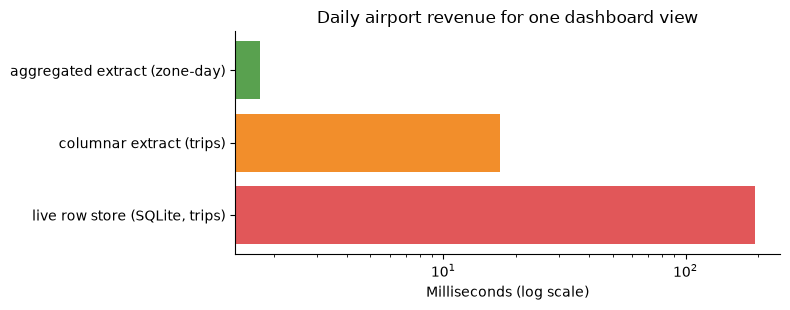

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(list(timings), list(timings.values()), color=["#E15759", "#F28E2B", "#59A14F"])
ax.set(xscale="log", title="Daily airport revenue for one dashboard view", xlabel="Milliseconds (log scale)")
plt.tight_layout()
plt.show()

## 5. Performance Checklist for Slow Workbooks

| Area | Check |
| :--- | :--- |
| data | extract instead of live for heavy analytics; aggregate the extract; hide unused fields |
| model | relationships instead of joins between different grains; no unnecessary blends |
| filters | context filters for large reductions; avoid "only relevant values" on many filters |
| calculations | prefer row-level calculations that the extract can materialise; avoid many nested LODs |
| views | fewer marks per sheet (thousands, not millions); fewer sheets per dashboard |
| diagnose | Tableau's *Performance Recorder* shows which query or layout step is slow |

*Insight: Model tables at their natural grain and let relationships aggregate before combining; use joins only between tables of the same grain. For speed, give the dashboard an extract at the level of detail it actually shows.*

## Real-World Use Case or Analogy

Joining tables of different grain is like **printing the annual budget on every single receipt**, then adding up the receipts' budgets: the sum is huge and meaningless. A relationship keeps the budget in its own book and compares it with the receipt total only when you ask.

Wrong totals from fan-out are one of the most common bugs in enterprise BI. The same modelling ideas apply in Power BI (Lesson 13), Looker (explores with join relationships) and dbt semantic models (M11).